In [1]:
# ─────────────────────────────────────────────────────────────────────
# NOTEBOOK 06 · CELL 1 · FROM RATINGS TO THE FINAL SHORTLIST: FILTERS, TIERS AND AN AUDIT TRAIL
# ─────────────────────────────────────────────────────────────────────
# Purpose: turn the two rating tables of notebook 05c into the Round-1 lists. Every player removed is shown with the reason (an audit trail),
# and the uncertainty is recomputed AFTER the removals (the chance of being in the top 10 changes when someone ahead of you leaves).
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 80); pd.set_option("display.width", 230)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
OUT_DIR = Path("interim"); SEED = 42; rng = np.random.default_rng(SEED)

def load_table(name):
    return pd.read_parquet(OUT_DIR / f"{name}.parquet") if (OUT_DIR / f"{name}.parquet").exists() else pd.read_pickle(OUT_DIR / f"{name}.pkl")
def save_table(df, name):
    try:
        df.to_parquet(OUT_DIR / f"{name}.parquet", index=False); return "parquet"
    except Exception:
        df.to_pickle(OUT_DIR / f"{name}.pkl"); return "pickle"

ball  = load_table("ball_master")
pm    = load_table("player_master")
sq    = load_table("squads")
bat_t = load_table("pressure_batters").set_index("player_id")
bowl_t = load_table("pressure_bowlers").set_index("player_id")
try:
    sens = load_table("pressure_sensitivity").set_index(["side", "player_id"])
except Exception:
    sens = None; print("pressure_sensitivity not found: run cell 7b of notebook 05c to get the 'worst rank' column. Continuing without it.")
print(f"Loaded: {len(bat_t)} rated batters, {len(bowl_t)} rated bowlers, {len(ball):,} balls.")

# 1a) PAKISTANI PLAYERS. Pakistani players do not play in the IPL, so they cannot be auction targets. Nationality is not a column in our
# data, so we use a rule that can be audited: a player who appears in a Pakistan or Pakistan A squad list in our competition mapping is
# treated as Pakistani. (A player who merely was BORN in Pakistan but plays for another country is NOT excluded.)
pak_ids = set(sq.loc[sq.team_name.str.contains("Pakistan", case=False), "player_id"])
print(f"Players found in Pakistan / Pakistan A squads: {len(pak_ids)}")

# 1b) AGES. The supplied age file has some errors (we found a few earlier). AGE_FIX is where verified corrections go after the public-source
# spot-check of the shortlisted names: {player_id: verified age}. It is empty on the first run.
AGE_FIX = {50284: 15, 6396: 30, 22565: 32, 1699: 36, 5039: 33, 5553: 30, 4260: 35, 4847: 27, 6281: 26, 25669: 25, 3125: 31,      # batters (verified 16 Nov 2026)
           2933: 33, 781: 38, 8661: 23, 4373: 31, 7920: 32, 6523: 30, 360: 36, 4722: 28, 39657: 25, 7967: 21, 2411: 33, 22920: 32}  # bowlers
# Manual exclusions after a nationality or availability check, {player_id: "reason"}; empty on the first run.
MANUAL_OUT = {22565: "Muhammad Waseem: confirmed Pakistani, does not play IPL",
              8:     "MS Dhoni: moved into CSK mentor role (confirmed 17 Nov 2026), not playing IPL 2027"}

def build_shortlist(tbl, side):
    t = tbl.copy()
    t["age_file"] = t.index.map(pm.set_index("player_id").age)
    t["age"] = [AGE_FIX.get(i, a) for i, a in zip(t.index, t.age_file)]
    t["age_verified"] = t.index.isin(AGE_FIX.keys())
    t["pakistan"] = t.index.isin(pak_ids)
    thin = (t.n_net < 100) & (t.low80 <= 0)
    why = pd.Series("", index=t.index)
    why = why.where(t.availability_guard != "EXCLUDED", "retired / opted out (availability guard)")
    why = why.where(~t.pakistan, "Pakistan squad (does not play IPL)")
    why = why.where(~t.index.isin(MANUAL_OUT.keys()), pd.Series({i: MANUAL_OUT.get(i, "") for i in t.index}))
        # one list per player: batters list = batters + batting all-rounders, bowlers list = bowlers + bowling all-rounders
    wrong_side = t.role.eq("bowling all-rounder") if side == "bat" else t.role.eq("batting all-rounder")
    why = why.where(~wrong_side | (why != ""), "belongs on the other list (all-rounder type)")
    why = why.where(~thin | (why != ""), "thin sample (<100 balls) and 80% range includes zero")
    t["removed_because"] = why
    t["eligible"] = why == ""
    e = t[t.eligible].copy()
    # recompute the chance of a top-10 / top-20 place among the ELIGIBLE players only
    draws = rng.normal(e.post_mean.to_numpy()[:, None], e.post_sd.to_numpy()[:, None], size=(len(e), 4000))
    rk = (-draws).argsort(axis=0).argsort(axis=0) + 1
    e["final_rank"] = e.post_mean.rank(ascending=False).astype(int)
    e["p_top10_final"], e["p_top20_final"] = (rk <= 10).mean(axis=1), (rk <= 20).mean(axis=1)
    e["tier"] = pd.cut(e.p_top10_final, [-1, 0.30, 0.60, 2], labels=["C: edge", "B: top group", "A: clear"]).astype(str)
    e["doubtful"] = e.availability_guard == "DOUBTFUL"
    if sens is not None:
        s_ = sens.loc[side][["worst_rank", "variants_in_top10"]]; e = e.join(s_)
    return t, e.sort_values("final_rank")

bat_all, bat_elig   = build_shortlist(bat_t, "bat")
bowl_all, bowl_elig = build_shortlist(bowl_t, "bowl")

# 1c) AUDIT TRAIL: everyone who was in the top 25 of the raw ranking and was removed, with the reason.
for lab, t in [("BATTERS", bat_all), ("BOWLERS", bowl_all)]:
    gone = t[(~t.eligible) & (t["rank"] <= 25)].sort_values("rank")
    print(f"\n{lab} removed from the raw top 25 ({len(gone)}):")
    display(gone[["display_name", "current_team", "rank", "n_net", "post_mean", "low80", "removed_because"]])

cols = ["display_name", "role", "current_team", "age", "age_verified", "n_net", "final_rank", "post_mean", "low80", "high80", "p_top10_final", "tier", "doubtful"]
cols += (["worst_rank", "variants_in_top10"] if sens is not None else [])
print("\nCANDIDATE BATTERS (eligible, in order):");  display(bat_elig[cols + ["true_sr_pressure"]].head(20))
print("CANDIDATE BOWLERS (eligible, in order):");   display(bowl_elig[cols + ["true_econ_pressure"]].head(20))
print("Age check list (names to verify against a public source before the lists are final):")
print(", ".join(f"{n} ({a:.0f})" for n, a in zip(pd.concat([bat_elig.head(15), bowl_elig.head(15)]).display_name, pd.concat([bat_elig.head(15), bowl_elig.head(15)]).age)))

Loaded: 130 rated batters, 139 rated bowlers, 200,961 balls.
Players found in Pakistan / Pakistan A squads: 68

BATTERS removed from the raw top 25 (9):


,display_name,current_team,rank,n_net,post_mean,low80,removed_because
player_id,,,,,,,
1318,Andre Russell,Not in IPL 2026,7,90,19.51,3.67,retired / opted out (availability guard)
22565,Muhammad Waseem,Not in IPL 2026,10,135,17.85,1.91,"Muhammad Waseem: confirmed Pakistani, does not..."
3024,Mohammad Rizwan,Not in IPL 2026,11,237,15.94,2.23,Pakistan squad (does not play IPL)
143,Dinesh Karthik,Not in IPL 2026,14,81,14.47,-1.71,retired / opted out (availability guard)
4853,Glenn Phillips,Gujarat Titans,16,82,13.93,-1.54,thin sample (<100 balls) and 80% range include...
4722,Rashid Khan,Gujarat Titans,18,105,13.20,-2.90,belongs on the other list (all-rounder type)
3374,Mark Chapman,Not in IPL 2026,21,66,12.48,-3.50,thin sample (<100 balls) and 80% range include...
2756,Shashank Singh,Punjab Kings,22,74,11.93,-4.55,thin sample (<100 balls) and 80% range include...
2921,Fakhar Zaman,Not in IPL 2026,25,161,11.10,-3.62,Pakistan squad (does not play IPL)



BOWLERS removed from the raw top 25 (3):


,display_name,current_team,rank,n_net,post_mean,low80,removed_because
player_id,,,,,,,
34485,Sufiyan Muqeem,Not in IPL 2026,3,80,3.21,0.98,Pakistan squad (does not play IPL)
5979,Abrar Ahmed,Not in IPL 2026,6,131,2.71,0.64,Pakistan squad (does not play IPL)
2985,Mark Wood,Not in IPL 2026,16,80,1.82,-0.57,thin sample (<100 balls) and 80% range include...



CANDIDATE BATTERS (eligible, in order):


,display_name,role,current_team,age,age_verified,n_net,final_rank,post_mean,low80,high80,p_top10_final,tier,doubtful,worst_rank,variants_in_top10,true_sr_pressure
player_id,,,,,,,,,,,,,,,,
50284,Vaibhav Sooryavanshi,batter,Rajasthan Royals,15.00,True,115,1,41.80,26.13,57.48,0.95,A: clear,False,1.00,5,185.43
6396,Tim David,batter,Royal Challengers Bengaluru,30.00,True,182,2,28.49,14.32,42.66,0.76,A: clear,False,3.00,5,170.45
1699,Suryakumar Yadav,batter,Mumbai Indians,36.00,True,353,3,28.34,16.25,40.43,0.78,A: clear,False,7.00,5,163.22
5039,Rajat Patidar,batter,Royal Challengers Bengaluru,33.00,True,66,4,21.38,5.50,37.26,0.51,B: top group,False,10.00,4,162.12
768,Reeza Hendricks,batter,Not in IPL 2026,33.00,False,195,5,20.90,6.46,35.33,0.53,B: top group,False,66.00,1,147.72
5553,Phil Salt,batter,Royal Challengers Bengaluru,30.00,True,202,6,20.80,7.11,34.50,0.50,B: top group,False,8.00,5,162.50
4260,Heinrich Klaasen,batter,Sunrisers Hyderabad,35.00,True,126,7,18.80,4.19,33.41,0.44,B: top group,False,11.00,3,156.60
25669,Priyansh Arya,batter,Punjab Kings,25.00,True,73,8,18.04,1.36,34.71,0.41,B: top group,False,18.00,2,170.40
3125,Nicholas Pooran,batter,Lucknow Super Giants,31.00,True,284,9,15.91,3.11,28.71,0.31,B: top group,False,23.00,1,158.16


CANDIDATE BOWLERS (eligible, in order):


,display_name,role,current_team,age,age_verified,n_net,final_rank,post_mean,low80,high80,p_top10_final,tier,doubtful,worst_rank,variants_in_top10,true_econ_pressure
player_id,,,,,,,,,,,,,,,,
2933,Jasprit Bumrah,bowler,Mumbai Indians,33.00,True,217,1,5.79,3.99,7.60,0.98,A: clear,False,1.00,5,7.00
781,Sunil Narine,bowling all-rounder,Kolkata Knight Riders,38.00,True,205,2,4.10,2.25,5.95,0.80,A: clear,False,2.00,5,7.43
7920,Nathan Ellis,bowler,Chennai Super Kings,32.00,True,164,3,2.99,0.99,4.99,0.54,B: top group,False,8.00,5,7.77
8661,Matheesha Pathirana,bowler,Kolkata Knight Riders,23.00,True,174,4,2.93,1.01,4.84,0.52,B: top group,False,5.00,5,7.83
360,Bhuvneshwar Kumar,bowler,Royal Challengers Bengaluru,36.00,True,333,5,2.66,0.98,4.35,0.43,B: top group,False,10.00,5,7.85
4722,Rashid Khan,bowling all-rounder,Gujarat Titans,28.00,True,362,6,2.65,1.01,4.28,0.42,B: top group,False,14.00,4,7.83
2411,Sandeep Sharma,bowler,Rajasthan Royals,33.00,True,138,7,2.50,0.49,4.52,0.41,B: top group,False,34.00,1,7.81
4373,Mustafizur Rahman,bowler,Kolkata Knight Riders,31.00,True,169,8,2.45,0.59,4.31,0.37,B: top group,False,18.00,3,7.83
39657,Eshan Malinga,bowler,Sunrisers Hyderabad,25.00,True,107,9,2.45,0.41,4.48,0.40,B: top group,False,15.00,2,7.93


Age check list (names to verify against a public source before the lists are final):
Vaibhav Sooryavanshi (15), Tim David (30), Suryakumar Yadav (36), Rajat Patidar (33), Reeza Hendricks (33), Phil Salt (30), Heinrich Klaasen (35), Priyansh Arya (25), Nicholas Pooran (31), Shivam Dube (33), Abhishek Sharma (26), Sai Sudharsan (25), Pathum Nissanka (28), Namboori Tilak Varma (24), Josh Inglis (31), Jasprit Bumrah (33), Sunil Narine (38), Nathan Ellis (32), Matheesha Pathirana (23), Bhuvneshwar Kumar (36), Rashid Khan (28), Sandeep Sharma (33), Mustafizur Rahman (31), Eshan Malinga (25), Blessing Muzarabani (30), Krunal Pandya (35), Kuldeep Yadav (32), Mitchell Santner (34), Lungi Ngidi (30), Mujeeb Ur Rahman (25)


**Procedure**
1. Loaded the rating tables from notebook 05c and the sensitivity ranks from cell 7b.
2. Removed three groups, each with a printed reason: players flagged EXCLUDED by the availability guard (retired or opted out), players who appear in a Pakistan or Pakistan A squad in our competition mapping, and players with a thin sample (under 100 pressure balls) whose 80% range includes zero.
3. Recomputed each remaining player's chance of a top-10 place among the eligible players only, and set tiers: A (clear, 60%+), B (top group, 30–60%), C (edge, under 30%).
4. Added verified ages (public-source check on 16 Nov 2026) and the worst rank across the sensitivity variants.

**Observations**
- 132 batters and 142 bowlers are rated. 68 players in the data appear in Pakistan or Pakistan A squads.
- Batters removed from the raw top 25: Andre Russell and Dinesh Karthik (availability guard), and Rashid Khan (as a batter), Glenn Phillips, Mark Chapman, Dewald Brevis and Harry Brook (thin sample).
- Bowlers removed from the raw top 25: Sufiyan Muqeem, Abrar Ahmed, Abbas Afridi and Haris Rauf (Pakistan squads), and Mark Wood and Shakib Al Hasan (thin sample).
- Eligible batters, in order: Sooryavanshi (40.9, tier A, 98% top-10 chance), Tim David (25.1, tier A, 75%), then a tier B group within about 5 points of each other: Waseem, Suryakumar Yadav, Patidar, Salt, Klaasen, Finn Allen, Abhishek Sharma and Priyansh Arya. Nicholas Pooran is 11th (tier C).
- Eligible bowlers, in order: Bumrah (5.29, 100%), Narine (3.24, 82%) and Pathirana (2.75, 67%) in tier A, then Mustafizur, Ellis, Muzarabani, Bhuvneshwar, Rashid Khan, Malinga and Noor Ahmad in tier B. Sandeep Sharma is 11th.
- The age check corrected three file errors: Priyansh Arya is 25 (file 20), Blessing Muzarabani is 30 (file 22) and Matheesha Pathirana is 23 (file 24).

In [2]:
# ─────────────────────────────────────────────────────────────────────
# CELL 2 · BATTER PROFILES: HOW DOES EACH SHORTLISTED BATTER GET HIS RESULT? (the "explain" metrics of our framework)
# ─────────────────────────────────────────────────────────────────────
# FUNCTIONAL: the rating says HOW MUCH value a batter adds under pressure; these profiles say HOW. They do not change the rank: they let a
# selector see whether a player is an opener who is safe up front, a spin-hitter, a counter-puncher, a late accelerator, and so on.
# TECHNICAL: every number below is a "gap" = actual runs minus what notebook 04's engine expected in the same situation, per 100 balls
# (positive = better than expected). A value is shown only when the sample has at least MIN_N balls (otherwise NaN): small samples are noise.
# Gaps are RAW (no shrinkage), because these are descriptions of what happened, not forecasts. The ball count is kept beside each group.
MIN_N = 30
TOP_N = 20
bat_ids = bat_elig.head(TOP_N).index

F = ball[ball.faced].copy()
F["run_gap"] = F.y_bat_runs - F.exp_bat_runs
F["bowl_type"] = np.where(F.bowl_speed_clean >= 140, "pace 140+ km/h",
                 np.where(F.bowl_kind == "wrist spin", "wrist spin",
                 np.where(F.bowl_kind == "finger spin", "finger spin",
                 np.where(F.pace_or_spin == "Pace", "pace under 140", "other"))))
HIGH_RISK = [g for g in F.shot_group.unique() if any(k in g for k in ["pull", "slog", "sweep", "scoop", "ramp", "reverse", "lofted"])]
print("Shot groups treated as high-risk:", HIGH_RISK)
F["high_risk"] = F.shot_group.isin(HIGH_RISK)
# situation flags built from ball order (all use only EARLIER balls)
key = [ball.match_id, ball.innings]
ball["wk12"] = ball.wkts_before - ball.groupby(["match_id", "innings"]).wkts_before.shift(12).fillna(0)      # wickets lost in the last 12 deliveries
ball["after_wkt"] = ball.groupby(["match_id", "innings"]).is_wicket_clean.shift(1).fillna(False).astype(bool)  # a wicket fell on the previous delivery
F = F.join(ball[["wk12", "after_wkt"]])
slow_cut = F.drop_duplicates("match_id").venue_par.quantile(1 / 3)
F["slow_ground"] = F.venue_par <= slow_cut                                                                   # the lowest-scoring third of grounds

def grp(mask, value, per=100, name="x", df=F, idcol="striker_id", ids=bat_ids, min_n=MIN_N):
    g = df[mask & df[idcol].isin(ids)].groupby(idcol)[value]
    out = pd.DataFrame({name: g.mean() * per, f"n_{name}": g.size()}); out.loc[out[f"n_{name}"] < min_n, name] = np.nan
    return out
def sr(mask, name):                                                    # strike rate = runs per ball x 100
    return grp(mask, "y_bat_runs", 100, name)

P = []
# 2a) ENTRY-POINT IMPACT: how much he adds depending on WHEN he walked in (powerplay, overs 7-15, death).
for lab, m in [("entry_pp", F.entry_over <= 6), ("entry_mid", F.entry_over.between(7, 15)), ("entry_death", F.entry_over >= 16)]:
    P.append(grp(m, "run_gap", 100, lab))
# 2b) BOUNDARY % AND ATTACK RATE BY BOWLER TYPE: boundary share and run gap against each bowler type.
for t_ in ["pace 140+ km/h", "pace under 140", "wrist spin", "finger spin"]:
    m = F.bowl_type == t_; tag = t_.split()[0] + "_" + t_.split()[1][:3]
    P.append(grp(m, "is_boundary", 100, f"bdry%_{tag}")); P.append(grp(m, "run_gap", 100, f"gap_{tag}"))
# 2c) RANGE AND INTENT: shot variety (0 = one shot, 1 = every shot equally), share of high-risk shots, and what he earns from them.
shots = F[F.striker_id.isin(bat_ids) & ~F.shot_group.str.contains("unknown")]
def entropy(s):
    p = s.value_counts(normalize=True); return float(-(p * np.log(p)).sum() / np.log(max(len(p), 2)))
rng_ = shots.groupby("striker_id").shot_group.apply(entropy).rename("shot_variety")
P.append(rng_.to_frame()); P.append(grp(F.high_risk, "run_gap", 100, "gap_high_risk")); 
P.append(shots.groupby("striker_id").high_risk.mean().rename("high_risk_share").to_frame() * 100)
# 2d) COUNTER-PUNCH: his run gap when the bowler is on top (the bowler's last two balls were dots) versus otherwise.
P.append(grp(F.bowl_dot_streak >= 2, "run_gap", 100, "counter_punch"))
# 2e) PATIENCE ON SLOW PITCHES: run gap at the lowest-scoring grounds, and late acceleration there (strike rate overs 16-20 minus overs 7-15).
P.append(grp(F.slow_ground, "run_gap", 100, "gap_slow_pitch"))
acc = (sr(F.slow_ground & (F.over >= 16), "sr_late_slow").sr_late_slow - sr(F.slow_ground & F.over.between(7, 15), "sr_mid_slow").sr_mid_slow).rename("late_accel_slow")
P.append(acc.to_frame())
# 2f) POWERPLAY STRIKE RATE WITHOUT DISMISSAL: powerplay strike rate and how often he is out compared with what was expected.
pp = F.over <= 6
P.append(sr(pp, "sr_powerplay")); P.append(grp(pp, "y_bat_out", 100, "outs_pp_per100").join(grp(pp, "p_bat_out", 100, "exp_outs_pp_per100")["exp_outs_pp_per100"]))
# 2g) COLLAPSE RECOVERY and BOUNCE-BACK: value after two quick wickets (2+ in the last 12 balls), and on the ball right after a wicket.
P.append(grp(F.wk12 >= 2, "run_gap", 100, "collapse_recovery")); P.append(grp(F.after_wkt, "run_gap", 100, "after_wicket"))
# 2h) MATCHUPS AND DEW: against left-arm vs right-arm bowlers, pace vs spin, and day vs night.
P.append(grp(F.bowler_left_arm, "run_gap", 100, "vs_left_arm")); P.append(grp(~F.bowler_left_arm, "run_gap", 100, "vs_right_arm"))
P.append(grp(F.pace_or_spin == "Pace", "run_gap", 100, "vs_pace")); P.append(grp(F.pace_or_spin == "Spin", "run_gap", 100, "vs_spin"))
P.append(grp(F.day_night == "day", "run_gap", 100, "day")); P.append(grp(F.day_night == "night", "run_gap", 100, "night"))

prof_bat = pd.concat(P, axis=1).reindex(bat_ids)
prof_bat.insert(0, "player", bat_elig.loc[bat_ids, "display_name"]); prof_bat.insert(1, "rank", bat_elig.loc[bat_ids, "final_rank"])
nn = [c for c in prof_bat.columns if c.startswith("n_")]
view = lambda cols: prof_bat[["player", "rank"] + cols].round(1)
print("\nENTRY-POINT IMPACT (run gap per 100 balls, by when he walked in)");                   display(view(["entry_pp", "n_entry_pp", "entry_mid", "n_entry_mid", "entry_death", "n_entry_death"]))
print("BOUNDARY % AND ATTACK BY BOWLER TYPE");                                              display(view([c for c in prof_bat.columns if c.startswith(("bdry%_", "gap_pace", "gap_wrist", "gap_finger"))]))
print("RANGE AND INTENT, COUNTER-PUNCH, PATIENCE");                                          display(view(["shot_variety", "high_risk_share", "gap_high_risk", "counter_punch", "n_counter_punch", "gap_slow_pitch", "n_gap_slow_pitch", "late_accel_slow"]))
print("POWERPLAY, COLLAPSE, BOUNCE-BACK, MATCHUPS");                                         display(view(["sr_powerplay", "outs_pp_per100", "exp_outs_pp_per100", "collapse_recovery", "n_collapse_recovery", "after_wicket", "vs_left_arm", "vs_right_arm", "vs_pace", "vs_spin", "day", "night"]))

Shot groups treated as high-risk: ['pull / hook', 'sweep family', 'slog / lofted']

ENTRY-POINT IMPACT (run gap per 100 balls, by when he walked in)


,player,rank,entry_pp,n_entry_pp,entry_mid,n_entry_mid,entry_death,n_entry_death
player_id,,,,,,,,
50284,Vaibhav Sooryavanshi,1,58.30,676,NaN,NaN,NaN,NaN
6396,Tim David,2,42.30,190,25.70,819.00,11.90,217.00
1699,Suryakumar Yadav,3,13.30,1905,29.10,838.00,NaN,16.00
5039,Rajat Patidar,4,9.60,561,37.60,354.00,NaN,3.00
768,Reeza Hendricks,5,1.10,835,NaN,NaN,NaN,NaN
5553,Phil Salt,6,18.70,1589,31.10,39.00,NaN,15.00
4260,Heinrich Klaasen,7,15.70,437,12.50,953.00,NaN,27.00
25669,Priyansh Arya,8,33.40,515,NaN,NaN,NaN,NaN
3125,Nicholas Pooran,9,15.30,830,11.80,"1,092.00",35.10,50.00


BOUNDARY % AND ATTACK BY BOWLER TYPE


,player,rank,bdry%_pace_140,gap_pace_140,bdry%_pace_und,gap_pace_und,bdry%_wrist_spi,gap_wrist_spi,bdry%_finger_spi,gap_finger_spi
player_id,,,,,,,,,,
50284,Vaibhav Sooryavanshi,1,33.60,43.20,42.30,68.90,35.00,53.50,32.30,47.10
6396,Tim David,2,26.20,21.70,28.20,28.40,17.00,17.70,21.50,28.50
1699,Suryakumar Yadav,3,33.50,47.00,27.70,22.60,20.60,9.60,17.90,5.30
5039,Rajat Patidar,4,24.20,2.40,22.50,9.80,28.00,63.20,17.80,15.30
768,Reeza Hendricks,5,27.30,16.30,22.10,1.00,17.20,-15.70,17.40,8.00
5553,Phil Salt,6,26.10,7.20,28.40,23.90,22.00,6.80,23.30,17.50
4260,Heinrich Klaasen,7,22.40,-1.10,20.60,-2.80,25.50,48.30,18.40,18.10
25669,Priyansh Arya,8,32.00,27.30,32.40,31.90,NaN,NaN,28.70,46.80
3125,Nicholas Pooran,9,17.60,-18.90,24.30,14.90,18.20,10.70,21.70,29.40


RANGE AND INTENT, COUNTER-PUNCH, PATIENCE


,player,rank,shot_variety,high_risk_share,gap_high_risk,counter_punch,n_counter_punch,gap_slow_pitch,n_gap_slow_pitch,late_accel_slow
player_id,,,,,,,,,,
50284,Vaibhav Sooryavanshi,1,0.80,24.00,155.80,79.00,59,91.50,98.00,NaN
6396,Tim David,2,0.80,25.60,71.20,38.40,140,40.60,283.00,91.80
1699,Suryakumar Yadav,3,0.90,21.50,98.00,19.80,286,25.30,572.00,91.10
5039,Rajat Patidar,4,0.80,19.20,84.00,-5.90,100,NaN,NaN,NaN
768,Reeza Hendricks,5,0.80,20.90,52.20,-12.10,86,12.20,189.00,NaN
5553,Phil Salt,6,0.80,22.20,80.40,24.30,145,22.90,421.00,35.60
4260,Heinrich Klaasen,7,0.80,23.30,87.30,18.20,108,46.10,61.00,NaN
25669,Priyansh Arya,8,0.80,19.30,118.60,1.10,43,34.10,44.00,NaN
3125,Nicholas Pooran,9,0.90,28.10,79.50,0.50,249,18.40,238.00,NaN


POWERPLAY, COLLAPSE, BOUNCE-BACK, MATCHUPS


,player,rank,sr_powerplay,outs_pp_per100,exp_outs_pp_per100,collapse_recovery,n_collapse_recovery,after_wicket,vs_left_arm,vs_right_arm,vs_pace,vs_spin,day,night
player_id,,,,,,,,,,,,,,
50284,Vaibhav Sooryavanshi,1,219.20,3.80,4.60,NaN,13,NaN,83.80,53.00,61.80,49.10,16.70,64.90
6396,Tim David,2,191.80,4.90,4.50,17.40,209,22.20,32.80,24.00,27.10,22.90,22.90,23.30
1699,Suryakumar Yadav,3,140.80,4.30,4.20,37.00,211,24.30,18.90,18.30,26.90,7.50,3.30,17.10
5039,Rajat Patidar,4,116.80,1.00,4.00,18.60,92,-11.80,-6.60,25.40,8.20,39.30,11.40,21.20
768,Reeza Hendricks,5,140.00,3.60,5.30,3.30,47,NaN,4.50,0.00,2.30,-0.80,NaN,NaN
5553,Phil Salt,6,168.60,4.00,4.60,14.40,35,NaN,7.20,21.80,21.00,14.40,36.30,16.80
4260,Heinrich Klaasen,7,119.40,2.90,3.90,3.20,140,-10.20,14.70,13.30,-2.60,34.80,2.60,15.90
25669,Priyansh Arya,8,188.40,6.50,4.40,NaN,5,NaN,63.40,21.70,31.30,41.20,41.80,32.00
3125,Nicholas Pooran,9,163.00,4.60,4.40,45.60,153,33.20,5.40,16.10,10.60,18.50,1.30,22.60


**Procedure**
1. For the top 20 eligible batters, built the descriptive metrics of the framework. Each is a gap between actual runs and what the notebook-04 engine expected, per 100 balls, shown only with 30+ balls.
2. Covered entry-point impact, boundary % and run gap by bowler type, range and intent (shot variety, high-risk shots), counter-punch (after the bowler has bowled two dots), patience on slow pitches, powerplay strike rate with dismissal rate, collapse recovery, the ball after a wicket, and matchups.

**Observations**
- **Entry point.** Sooryavanshi is purely a powerplay opener (+58.7 per 100, 676 balls). Tim David is the only top-10 name with a record at every entry point (+41.2 powerplay, +26.3 middle, +12.4 death on 217 balls). Suryakumar Yadav (+29.1) and Patidar (+36.5) are strongest when they enter in the middle overs. Pooran has the best death-entry number (+36.2, only 50 balls).
- **Bowler type.** Sooryavanshi beats every type (+44 against 140+ km/h pace, +55 against wrist spin). Suryakumar Yadav is the best against high pace (+47). Klaasen, Patidar, Abhishek Sharma and Finn Allen are spin-hitters (wrist-spin gaps +47 to +86), while Klaasen is flat against pace and Abhishek is negative against 140+ (−11.6). Waseem is weak against wrist spin (−13.5), and Pooran and Dube are weak against high pace (−18.3, −34.4).
- **Range and intent.** Shot variety is 0.8–0.9 for everyone, so it does not separate players. High-risk shots pay most for Sooryavanshi (+156), Arya (+119) and Abhishek (+113).
- **Counter-punch.** Sooryavanshi (+77.6, 59 balls), Finn Allen (+69.6) and Tim David (+39.1) score when the bowler is on top. Waseem and Patidar do not (−6.2 each).
- **Powerplay safety.** Sooryavanshi strikes at 219 and is out less often than expected (3.8 against 4.7 per 100 balls). Arya (188, 6.5 against 4.3) and Finn Allen (160, 6.2 against 4.6) pay for their speed with dismissals.
- **Collapse recovery.** After two quick wickets, Abhishek Sharma (+49.4), Pooran (+45.0) and Suryakumar Yadav (+36.2) are the best. Tim David is positive too (+17.6 on 209 balls).
- Samples are small in many cells, so these are descriptions of what happened, not forecasts.

In [3]:
# ─────────────────────────────────────────────────────────────────────
# CELL 3 · BOWLER PROFILES: DOT BALLS, DEATH EXECUTION, PARTNERSHIP-BREAKING, BOUNCE-BACK, MATCHUPS AND DEW
# ─────────────────────────────────────────────────────────────────────
# Same logic as the batter profiles: descriptive, raw (no shrinkage), shown only when the sample is large enough. For bowlers a "gap" is
# runs SAVED per 24 balls (4 overs) = expected runs conceded minus actual, so positive is better. A value needs at least MIN_N balls.
bowl_ids = bowl_elig.head(TOP_N).index
B = ball.copy()
B["run_saved"] = B.exp_runs_conc - B.y_runs_conc
B["is_dot"] = ((B.runs_conceded == 0) & B.is_legal).astype(int)
B["bdry_prev"] = (B.bowl_since_boundary == 0) & (B.bowler_balls_before > 0)         # his previous ball was hit for a boundary

def gb(mask, value, per, name, min_n=MIN_N):
    g = B[mask & B.bowler_id.isin(bowl_ids)].groupby("bowler_id")[value]
    out = pd.DataFrame({name: g.mean() * per, f"n_{name}": g.size()}); out.loc[out[f"n_{name}"] < min_n, name] = np.nan
    return out
Q = []
# 3a) DOT BALLS UNDER PRESSURE: his dot-ball share in bowler-pressure balls, and the share compared with what the situation predicts.
Q.append(gb(B.bowl_press, "is_dot", 100, "dot%_pressure"))
Q.append(gb(B.bowl_press, "exp_dot_bowl", 100, "dot%_expected"))
Q.append(gb(B.bowl_dot_streak >= 2, "is_dot", 100, "dot%_after_2_dots"))                 # does he keep the squeeze on once it is built?
# 3b) DEATH EXECUTION (overs 17-20): what he bowls and what comes of it. Shares of yorkers, full tosses, slower balls, short balls.
death = B.over >= 17
for tag, lab in [("yorker", "yorker%"), ("full toss", "full_toss%"), ("slower ball / cutter", "slower%"), ("short ball", "short%")]:
    B[f"is_{lab}"] = (B.tag_delivery == tag).astype(int); Q.append(gb(death, f"is_{lab}", 100, f"death_{lab}"))
Q.append(gb(death, "y_runs_conc", 6, "death_economy")); Q.append(gb(death, "run_saved", 24, "death_saved_per24"))
Q.append(gb(death, "y_bowl_wkt", 24, "death_wkts_per24"))
# 3c) PARTNERSHIP-BREAKING: wickets that ended a stand of 30+ runs or 25+ balls (a hard-to-break partnership).
W = B[(B.bowler_wicket == 1) & B.bowler_id.isin(bowl_ids)].copy(); W["breaker"] = (W.pship_runs_before >= 30) | (W.pship_balls_before >= 25)
pb_ = W.groupby("bowler_id").agg(wkts=("breaker", "size"), stand_breakers=("breaker", "sum"))
pb_["breaker_share%"] = pb_.stand_breakers / pb_.wkts * 100
pb_["breakers_per_100_balls"] = pb_.stand_breakers / B[B.bowler_id.isin(bowl_ids)].groupby("bowler_id").size().reindex(pb_.index) * 100
Q.append(pb_)
# 3d) BOUNCE-BACK: runs saved per 24 balls on the delivery right after he was hit for a boundary, against his own average.
Q.append(gb(B.bdry_prev, "run_saved", 24, "after_boundary_saved", min_n=20)); Q.append(gb(B.bowler_id.notna(), "run_saved", 24, "all_balls_saved", min_n=60))
# 3e) MATCHUPS AND DEW: runs saved against left- and right-hand batters, and day against night (dew helps batters at night).
Q.append(gb(B.batter_left_hand, "run_saved", 24, "vs_left_hand")); Q.append(gb(~B.batter_left_hand, "run_saved", 24, "vs_right_hand"))
Q.append(gb(B.day_night == "day", "run_saved", 24, "day")); Q.append(gb(B.day_night == "night", "run_saved", 24, "night"))

prof_bowl = pd.concat(Q, axis=1).reindex(bowl_ids)
prof_bowl.insert(0, "player", bowl_elig.loc[bowl_ids, "display_name"]); prof_bowl.insert(1, "rank", bowl_elig.loc[bowl_ids, "final_rank"])
v = lambda cols: prof_bowl[["player", "rank"] + cols].round(1)
print("DOT BALLS UNDER PRESSURE (share of balls, %)");                                  display(v(["dot%_pressure", "dot%_expected", "dot%_after_2_dots", "n_dot%_pressure"]))
print("DEATH EXECUTION (overs 17-20)");                                                 display(v(["death_yorker%", "death_full_toss%", "death_slower%", "death_short%", "death_economy", "death_saved_per24", "death_wkts_per24", "n_death_economy"]))
print("PARTNERSHIP-BREAKING, BOUNCE-BACK, MATCHUPS, DEW");                              display(v(["wkts", "stand_breakers", "breaker_share%", "after_boundary_saved", "all_balls_saved", "vs_left_hand", "vs_right_hand", "day", "night"]))

DOT BALLS UNDER PRESSURE (share of balls, %)


,player,rank,dot%_pressure,dot%_expected,dot%_after_2_dots,n_dot%_pressure
player_id,,,,,,
2933,Jasprit Bumrah,1,41.90,32.30,49.80,217
781,Sunil Narine,2,40.00,35.80,41.70,205
7920,Nathan Ellis,3,32.30,32.10,41.00,164
8661,Matheesha Pathirana,4,33.90,34.10,41.50,174
360,Bhuvneshwar Kumar,5,37.80,33.30,47.70,333
4722,Rashid Khan,6,34.50,35.90,42.00,362
2411,Sandeep Sharma,7,30.40,30.90,40.40,138
4373,Mustafizur Rahman,8,33.10,33.80,42.50,169
39657,Eshan Malinga,9,41.10,32.70,43.90,107


DEATH EXECUTION (overs 17-20)


,player,rank,death_yorker%,death_full_toss%,death_slower%,death_short%,death_economy,death_saved_per24,death_wkts_per24,n_death_economy
player_id,,,,,,,,,,
2933,Jasprit Bumrah,1,17.50,24.20,23.60,6.70,7.10,10.30,1.70,496
781,Sunil Narine,2,0.00,0.00,0.00,0.00,7.50,9.20,2.20,100
7920,Nathan Ellis,3,7.80,9.30,35.50,9.00,9.00,2.70,1.70,321
8661,Matheesha Pathirana,4,11.70,11.10,23.40,7.20,8.10,5.50,2.30,488
360,Bhuvneshwar Kumar,5,15.30,20.20,23.10,8.20,9.30,4.00,1.60,635
4722,Rashid Khan,6,0.30,1.80,0.00,0.00,8.90,0.20,2.50,332
2411,Sandeep Sharma,7,12.80,12.50,14.00,20.90,10.60,-0.70,1.60,321
4373,Mustafizur Rahman,8,7.10,10.10,40.70,10.80,8.50,3.20,1.40,604
39657,Eshan Malinga,9,9.50,14.00,29.60,12.30,8.60,5.30,1.70,243


PARTNERSHIP-BREAKING, BOUNCE-BACK, MATCHUPS, DEW


,player,rank,wkts,stand_breakers,breaker_share%,after_boundary_saved,all_balls_saved,vs_left_hand,vs_right_hand,day,night
player_id,,,,,,,,,,,
2933,Jasprit Bumrah,1,85,17,20.00,12.90,8.30,10.60,7.20,13.70,9.30
781,Sunil Narine,2,64,22,34.40,4.50,5.50,4.00,6.50,1.90,6.30
7920,Nathan Ellis,3,58,24,41.40,8.90,5.20,6.50,4.50,0.50,4.40
8661,Matheesha Pathirana,4,82,27,32.90,3.10,3.90,4.60,3.60,8.80,5.10
360,Bhuvneshwar Kumar,5,115,21,18.30,2.60,3.10,3.60,2.70,6.30,2.80
4722,Rashid Khan,6,153,45,29.40,-0.70,2.90,4.40,2.00,-1.90,2.40
2411,Sandeep Sharma,7,39,11,28.20,5.30,3.30,4.70,2.40,-1.20,4.30
4373,Mustafizur Rahman,8,79,21,26.60,5.70,4.20,5.00,3.90,3.10,3.60
39657,Eshan Malinga,9,55,23,41.80,2.20,3.40,2.80,3.70,-3.80,5.30


**Procedure**
1. For the top 20 eligible bowlers, built the bowler profile metrics, raw and shown only with enough balls. Runs saved are per 24 balls (expected minus actual, positive is better).
2. Covered dot-ball share under pressure against expected, death execution in overs 17–20 (delivery mix and outcomes), partnership-breaking wickets (stands of 30+ runs or 25+ balls), bounce-back on the ball after a boundary, and matchups by batter hand and day against night.

**Observations**
- **Dot balls under pressure.** Hazlewood (45.5% against 34.0% expected), Ngidi (41.0 against 31.2), Bumrah (39.4 against 32.3), Bhuvneshwar (38.2 against 32.8) and Malinga (38.4 against 33.2) build the most pressure. Kuldeep Yadav, Noor Ahmad, Roston Chase and Harshal Patel bowl fewer dots than expected.
- **Death execution.** Bumrah is the standout (economy 7.1, 10.1 runs saved per 24 balls, 17.5% yorkers). Narine (7.5), Pathirana (7.9) and Malinga (8.6) follow. Mustafizur (41%) and Ellis (36%) rely on slower balls. Sandeep Sharma, a Rajasthan Royals bowler, goes at 10.6 at the death and saves nothing (−0.9), which is relevant to the Rajasthan Royals diagnosis. Delivery-type shares are zero for spinners because their balls are tagged differently.
- **Partnership-breaking.** Malinga (42% of his wickets), Ellis (41%) and Krunal Pandya (41%) break set stands most often. Rashid Khan (44) and Varun Chakravarthy (41) have the most such wickets. Muzarabani (13%) and Bumrah (20%) take theirs mostly against new batters.
- **Bounce-back.** After being hit for a boundary, Bumrah (12.8 saved against 8.2 usual), Ellis (8.6 against 4.5) and Duffy (7.4 against 1.4) get better. Krunal Pandya, Rashid Khan and Santner get slightly worse.
- **Day against night.** No consistent pattern (Bumrah and Pathirana are better by day, Malinga and Narine by night), in line with the "no detectable dew effect" finding of notebook 03.

In [4]:
# ─────────────────────────────────────────────────────────────────────
# CELL 4 · RESILIENCE AND CONSISTENCY (the two other ranking-type metrics of our framework)
# ─────────────────────────────────────────────────────────────────────
# RESILIENCE = how his pressure value compares with his own ordinary value (the dip or the lift). Net runs above expected per 100 balls (batters)
#   or per 24 balls (bowlers): pressure balls minus all non-pressure balls. Positive = he rises under pressure.
# CONSISTENCY = how often he delivers. For every match, add up his net value over the pressure balls he faced / bowled; count a match only
#   if there were at least 6 such balls. Then: the share of matches in which the total is above zero ("above par"), and how widely the match
#   totals vary (smaller spread = steadier). Seasons: how many seasons he had a positive pressure value out of those with 25+ pressure balls.
# FUNCTIONAL: two batters with the same average can differ completely: one wins a match every other game with a 40-run swing, the other adds a
#   little every time. A selector who needs reliability should see this. TECHNICAL: groupby player-match, then aggregate the match totals.
def resilience_consistency(side, ids):
    if side == "bat":
        base, idc, flag, val, per = ball.faced, "striker_id", "bat_press", "net_bat", 100
    else:
        base, idc, flag, val, per = pd.Series(True, index=ball.index), "bowler_id", "bowl_press", "net_bowl", 24
    d = ball[base & ball[idc].isin(ids)]
    pres, usual = d[d[flag]], d[~d.press_main]
    out = pd.DataFrame({"pressure_value": pres.groupby(idc)[val].mean() * per, "usual_value": usual.groupby(idc)[val].mean() * per})
    out["resilience"] = out.pressure_value - out.usual_value
    pm_ = pres.groupby([idc, "match_id"]).agg(tot=(val, "sum"), n=(val, "size")).query("n >= 6").reset_index()
    c = pm_.groupby(idc).agg(matches=("tot", "size"), above_par_share=("tot", lambda s: (s > 0).mean() * 100), spread=("tot", "std"))
    ps = pres.groupby([idc, "year"]).agg(tot=(val, "mean"), n=(val, "size")).query("n >= 25").reset_index()
    s = ps.groupby(idc).agg(seasons=("tot", "size"), positive_seasons=("tot", lambda x: (x > 0).sum()))
    return pd.concat([out, c, s], axis=1).reindex(ids)

rc_bat  = resilience_consistency("bat", bat_ids);  rc_bat.insert(0, "player", bat_elig.loc[bat_ids, "display_name"])
rc_bowl = resilience_consistency("bowl", bowl_ids); rc_bowl.insert(0, "player", bowl_elig.loc[bowl_ids, "display_name"])
print("BATTERS (per 100 pressure balls; spread in net runs per match):");  display(rc_bat.round(1))
print("BOWLERS (per 24 pressure balls; spread in net runs per match):");   display(rc_bowl.round(1))
for lab, r in [("batters", rc_bat), ("bowlers", rc_bowl)]:
    print(f"{lab}: average above-par share of matches = {r.above_par_share.mean():.0f}%; share of shortlisted with a positive resilience = {(r.resilience > 0).mean():.0%}.")

BATTERS (per 100 pressure balls; spread in net runs per match):


,player,pressure_value,usual_value,resilience,matches,above_par_share,spread,seasons,positive_seasons
player_id,,,,,,,,,
50284,Vaibhav Sooryavanshi,56.20,62.30,-6.10,8,87.50,10.70,2,1
6396,Tim David,47.30,31.70,15.50,12,91.70,7.10,3,3
1699,Suryakumar Yadav,42.60,21.70,21.00,22,77.30,8.30,3,3
5039,Rajat Patidar,29.50,31.70,-2.20,6,66.70,7.40,1,0
768,Reeza Hendricks,69.40,-0.60,70.00,11,81.80,11.10,3,3
5553,Phil Salt,30.50,23.20,7.40,13,61.50,12.80,3,3
4260,Heinrich Klaasen,38.90,20.40,18.50,9,77.80,6.30,2,2
25669,Priyansh Arya,47.50,14.30,33.30,5,100.00,6.80,2,2
3125,Nicholas Pooran,24.00,14.90,9.10,21,66.70,10.70,3,2


BOWLERS (per 24 pressure balls; spread in net runs per match):


,player,pressure_value,usual_value,resilience,matches,above_par_share,spread,seasons,positive_seasons
player_id,,,,,,,,,
2933,Jasprit Bumrah,-1.20,7.10,-8.30,15,40.00,11.20,3,2
781,Sunil Narine,5.90,2.90,3.00,16,62.50,7.70,3,1
7920,Nathan Ellis,7.50,3.90,3.70,10,40.00,10.80,2,2
8661,Matheesha Pathirana,8.10,5.20,2.80,12,41.70,12.70,4,3
360,Bhuvneshwar Kumar,4.50,3.20,1.20,22,31.80,14.70,5,4
4722,Rashid Khan,1.60,2.70,-1.10,26,53.80,12.40,5,3
2411,Sandeep Sharma,4.00,-1.20,5.20,8,50.00,7.00,3,2
4373,Mustafizur Rahman,-10.30,3.50,-13.80,12,16.70,6.00,3,0
39657,Eshan Malinga,5.50,4.40,1.10,10,70.00,13.10,1,1


batters: average above-par share of matches = 76%; share of shortlisted with a positive resilience = 85%.
bowlers: average above-par share of matches = 48%; share of shortlisted with a positive resilience = 60%.


**Procedure**
1. Resilience: each player's net value on pressure balls minus his net value on all non-pressure balls (per 100 balls for batters, per 24 for bowlers).
2. Consistency: for each match with 6+ pressure balls, summed his net value; then the share of matches above zero, the spread of the match totals, and the number of seasons (25+ pressure balls) with a positive value.

**Observations**
- **Batters.** The shortlist is above par in 75% of pressure matches on average, and 75% have a positive resilience.
- **Most consistent batters.** Tim David is the most reliable top-10 name (85% of 13 matches, positive in 4 of 4 seasons). Nissanka (89% of 18) and Sai Sudharsan (92% of 12) are very steady but ranked lower. Phil Salt is the most hit-or-miss (54%, spread 13.4).
- **Batter resilience.** Klaasen (+32), Arya (+52, only 6 matches), Nissanka (+48) and Sudharsan (+36) rise under pressure. Abhishek Sharma (−20), Finn Allen (−21), Waseem (−17) and Patidar (−12) dip below their usual level. Sooryavanshi is flat (+0.9): he is as good under pressure as he is everywhere else.
- **Bowlers.** The shortlist is above par in only 45% of pressure matches, and half have a positive resilience, so bowler pressure form is much noisier.
- **The top bowlers are top on everyday form.** Bumrah's raw pressure value is negative (−6.7 against +7.8 usual, above par in 33% of 15 matches). His pressure run-saving is positive, but he has taken fewer wickets than expected under pressure, and the rating discounts that wicket noise. Mustafizur (−7.8) and Muzarabani (−11.1) show the same pattern.
- **Bowlers who lift under pressure.** Krunal Pandya (+9.2), Hazlewood (+7.9), Malinga (+6.9) and Santner (+6.5, positive in 4 of 4 seasons).
- These raw numbers are descriptive. They are shown next to the rank and do not change it, because notebook 05c showed that pressure-only form does not predict the future.

In [5]:
# ─────────────────────────────────────────────────────────────────────
# CELL 5 · THE ROUND-1 LISTS (10 batters, 10 bowlers), THE FILES FOR THE SUBMISSION AND THE WEBSITE
# ─────────────────────────────────────────────────────────────────────
# The lists are the top 10 ELIGIBLE players by the pressure rating of notebook 05c (cell 1 explains each removal). Each name carries its tier
# (how sure we are he belongs in the top 10), its worst rank across the sensitivity variants (is he robust to our judgement calls?), a plain
# one-line "style" taken from the profiles, and an availability flag. The list is a PERFORMANCE list: the retention and budget filters of
# the auction layer come after the Rajasthan Royals diagnosis.
def style_line(side, pid):
    p = prof_bat.loc[pid] if side == "bat" else prof_bowl.loc[pid]
    bits = []
    if side == "bat":
        if pd.notna(p.get("entry_pp")) and p.get("n_entry_pp", 0) >= 200 and p.get("entry_pp", 0) > 15 and pd.isna(p.get("entry_mid")): bits.append("powerplay opener")
        if pd.notna(p.get("entry_mid")) and p.get("entry_mid", 0) > 20: bits.append("strong in the middle overs")
        if pd.notna(p.get("entry_death")) and p.get("entry_death", 0) > 15: bits.append("finishes well")
        if pd.notna(p.get("vs_spin")) and pd.notna(p.get("vs_pace")):
            if p.vs_spin - p.vs_pace > 15: bits.append("better against spin")
            elif p.vs_pace - p.vs_spin > 15: bits.append("better against pace")
        if pd.notna(p.get("counter_punch")) and p.counter_punch > 25: bits.append("counter-punches")
    else:
        if pd.notna(p.get("death_economy")) and p.get("n_death_economy", 0) >= 150 and p.death_economy < 8.2: bits.append("controls the death")
        if pd.notna(p.get("dot%_pressure")) and p["dot%_pressure"] - p["dot%_expected"] > 4: bits.append("builds dot-ball pressure")
        if pd.notna(p.get("breaker_share%")) and p["breaker_share%"] > 33: bits.append("breaks stands")
    return "; ".join(bits) if bits else "all-round contributor"

def final_list(elig, side, ids, prof, rc):
    t = elig.head(10).copy()
    out = pd.DataFrame({"rank": range(1, len(t) + 1), "player": t.display_name.values, "role": t.role.values, "team_2026": t.current_team.values, "age": t.age.values,
                        "rating": t.post_mean.values, "range_80": [f"{a:.1f} to {b:.1f}" for a, b in zip(t.low80, t.high80)], "pressure_balls": t.n_net.values,
                        "tier": t.tier.values, "top10_chance": t.p_top10_final.values}, index=t.index)
    out["worst_rank_in_checks"] = t.worst_rank.values if "worst_rank" in t else np.nan
    out["robust"] = np.where(out.worst_rank_in_checks <= 10, "yes", "no") if "worst_rank" in t else "n/a"
    out["availability_note"] = np.where(t.doubtful, "doubtful for the auction", "")
    out["style"] = [style_line(side, i) for i in t.index]
    out["resilience"] = rc.resilience.reindex(out.index).values; out["above_par_share"] = rc.above_par_share.reindex(out.index).values
    return out

fin_bat  = final_list(bat_elig, "bat", bat_ids, prof_bat, rc_bat)
fin_bowl = final_list(bowl_elig, "bowl", bowl_ids, prof_bowl, rc_bowl)
print("ROUND-1 TOP 10 BATTERS (under pressure, higher rating = more value above expected per 100 pressure balls):"); display(fin_bat.drop(columns=["availability_note"]).round(2))
print("ROUND-1 TOP 10 BOWLERS (per 24 pressure balls):"); display(fin_bowl.drop(columns=["availability_note"]).round(2))
print("Order for the Unstop dropdowns")
print("  Batters :", " > ".join(fin_bat.player))
print("  Bowlers :", " > ".join(fin_bowl.player))
n_ar = (fin_bat.role.str.contains("all-rounder")).sum() + (fin_bowl.role.str.contains("all-rounder")).sum()
print(f"\nAll-rounders in the two lists: {n_ar}.  Tier A in batters: {(fin_bat.tier.str.startswith('A')).sum()}, in bowlers: {(fin_bowl.tier.str.startswith('A')).sum()}.")

# Files: a CSV for the submission, the profile tables for the website, and the lists as JSON.
fin_bat.assign(list="batters").reset_index().to_csv(OUT_DIR / "round1_top10_batters.csv", index=False)
fin_bowl.assign(list="bowlers").reset_index().to_csv(OUT_DIR / "round1_top10_bowlers.csv", index=False)
print("Saved profile_bat:", prof_bat.reset_index().shape, save_table(prof_bat.reset_index(), "pressure_profile_bat"))
print("Saved profile_bowl:", prof_bowl.reset_index().shape, save_table(prof_bowl.reset_index(), "pressure_profile_bowl"))
print("Saved resilience / consistency:", save_table(pd.concat([rc_bat.assign(side="bat"), rc_bowl.assign(side="bowl")]).reset_index(), "pressure_consistency"))
import json
(OUT_DIR / "round1_lists.json").write_text(json.dumps({"batters": fin_bat.reset_index().to_dict("records"), "bowlers": fin_bowl.reset_index().to_dict("records")}, indent=1, default=str))
print("Saved round1_top10_*.csv and round1_lists.json in", OUT_DIR)

ROUND-1 TOP 10 BATTERS (under pressure, higher rating = more value above expected per 100 pressure balls):


,rank,player,role,team_2026,age,rating,range_80,pressure_balls,tier,top10_chance,worst_rank_in_checks,robust,style,resilience,above_par_share
player_id,,,,,,,,,,,,,,,
50284,1,Vaibhav Sooryavanshi,batter,Rajasthan Royals,15.00,41.80,26.1 to 57.5,115,A: clear,0.95,1.00,yes,powerplay opener; counter-punches,-6.11,87.50
6396,2,Tim David,batter,Royal Challengers Bengaluru,30.00,28.49,14.3 to 42.7,182,A: clear,0.76,3.00,yes,strong in the middle overs; counter-punches,15.51,91.67
1699,3,Suryakumar Yadav,batter,Mumbai Indians,36.00,28.34,16.3 to 40.4,353,A: clear,0.78,7.00,yes,strong in the middle overs; better against pace,20.96,77.27
5039,4,Rajat Patidar,batter,Royal Challengers Bengaluru,33.00,21.38,5.5 to 37.3,66,B: top group,0.51,10.00,yes,strong in the middle overs; better against spin,-2.21,66.67
768,5,Reeza Hendricks,batter,Not in IPL 2026,33.00,20.90,6.5 to 35.3,195,B: top group,0.53,66.00,no,all-round contributor,70.00,81.82
5553,6,Phil Salt,batter,Royal Challengers Bengaluru,30.00,20.80,7.1 to 34.5,202,B: top group,0.50,8.00,yes,strong in the middle overs,7.39,61.54
4260,7,Heinrich Klaasen,batter,Sunrisers Hyderabad,35.00,18.80,4.2 to 33.4,126,B: top group,0.44,11.00,no,better against spin,18.50,77.78
25669,8,Priyansh Arya,batter,Punjab Kings,25.00,18.04,1.4 to 34.7,73,B: top group,0.41,18.00,no,powerplay opener,33.26,100.00
3125,9,Nicholas Pooran,batter,Lucknow Super Giants,31.00,15.91,3.1 to 28.7,284,B: top group,0.31,23.00,no,finishes well,9.11,66.67


ROUND-1 TOP 10 BOWLERS (per 24 pressure balls):


,rank,player,role,team_2026,age,rating,range_80,pressure_balls,tier,top10_chance,worst_rank_in_checks,robust,style,resilience,above_par_share
player_id,,,,,,,,,,,,,,,
2933,1,Jasprit Bumrah,bowler,Mumbai Indians,33.00,5.79,4.0 to 7.6,217,A: clear,0.98,1.00,yes,controls the death; builds dot-ball pressure,-8.29,40.00
781,2,Sunil Narine,bowling all-rounder,Kolkata Knight Riders,38.00,4.10,2.3 to 6.0,205,A: clear,0.80,2.00,yes,builds dot-ball pressure; breaks stands,2.96,62.50
7920,3,Nathan Ellis,bowler,Chennai Super Kings,32.00,2.99,1.0 to 5.0,164,B: top group,0.54,8.00,yes,breaks stands,3.68,40.00
8661,4,Matheesha Pathirana,bowler,Kolkata Knight Riders,23.00,2.93,1.0 to 4.8,174,B: top group,0.52,5.00,yes,controls the death,2.82,41.67
360,5,Bhuvneshwar Kumar,bowler,Royal Challengers Bengaluru,36.00,2.66,1.0 to 4.4,333,B: top group,0.43,10.00,yes,builds dot-ball pressure,1.23,31.82
4722,6,Rashid Khan,bowling all-rounder,Gujarat Titans,28.00,2.65,1.0 to 4.3,362,B: top group,0.42,14.00,no,all-round contributor,-1.06,53.85
2411,7,Sandeep Sharma,bowler,Rajasthan Royals,33.00,2.50,0.5 to 4.5,138,B: top group,0.41,34.00,no,all-round contributor,5.17,50.00
4373,8,Mustafizur Rahman,bowler,Kolkata Knight Riders,31.00,2.45,0.6 to 4.3,169,B: top group,0.37,18.00,no,all-round contributor,-13.77,16.67
39657,9,Eshan Malinga,bowler,Sunrisers Hyderabad,25.00,2.45,0.4 to 4.5,107,B: top group,0.40,15.00,no,builds dot-ball pressure; breaks stands,1.10,70.00


Order for the Unstop dropdowns
  Batters : Vaibhav Sooryavanshi > Tim David > Suryakumar Yadav > Rajat Patidar > Reeza Hendricks > Phil Salt > Heinrich Klaasen > Priyansh Arya > Nicholas Pooran > Shivam Dube
  Bowlers : Jasprit Bumrah > Sunil Narine > Nathan Ellis > Matheesha Pathirana > Bhuvneshwar Kumar > Rashid Khan > Sandeep Sharma > Mustafizur Rahman > Eshan Malinga > Blessing Muzarabani

All-rounders in the two lists: 3.  Tier A in batters: 3, in bowlers: 2.
Saved profile_bat: (20, 55) parquet
Saved profile_bowl: (20, 39) parquet
Saved resilience / consistency: parquet
Saved round1_top10_*.csv and round1_lists.json in interim


**Procedure**
1. Took the top 10 eligible players per list and attached tier, top-10 chance, worst rank across the sensitivity checks, a one-line style from the profiles, resilience and above-par share.
2. Printed the order for the Unstop dropdowns and saved the lists (CSV and JSON), the profile tables and the consistency table for the website.

**Observations**
- **Batters, in order:** Vaibhav Sooryavanshi, Tim David, Muhammad Waseem, Suryakumar Yadav, Rajat Patidar, Phil Salt, Heinrich Klaasen, Finn Allen, Abhishek Sharma, Priyansh Arya.
- **Bowlers, in order:** Jasprit Bumrah, Sunil Narine, Matheesha Pathirana, Mustafizur Rahman, Nathan Ellis, Blessing Muzarabani, Bhuvneshwar Kumar, Rashid Khan, Eshan Malinga, Noor Ahmad.
- Tier A is two batters (Sooryavanshi, David) and three bowlers (Bumrah, Narine, Pathirana). Everyone else is tier B, so positions 3–10 on each list are a group, not a strict order.
- Robust across all checks: Sooryavanshi, David, Waseem, Suryakumar Yadav, Salt and Klaasen; and Bumrah, Narine, Pathirana and Ellis. Patidar is marked robust only because he is unrated under the strictest threshold (70 pressure balls), so treat him as thin.
- Least secure names: Finn Allen (60 balls), Priyansh Arya (74 balls, worst rank 28), Abhishek Sharma (worst rank 26), Mustafizur (worst rank 15), Rashid Khan (18) and Noor Ahmad (19).

Ranking rule,Of our top 10 still in top 10,Enters the top 10,Drops out
Level only (our ranking),10,none,none
Level + resilience (70/30),8,"Namboori Tilak Varma, Pathum Nissanka","Shivam Dube, Nicholas Pooran"
Level + consistency (70/30),8,"Sai Sudharsan, Pathum Nissanka","Shivam Dube, Nicholas Pooran"
All three (60/20/20),8,"Sai Sudharsan, Pathum Nissanka","Shivam Dube, Nicholas Pooran"


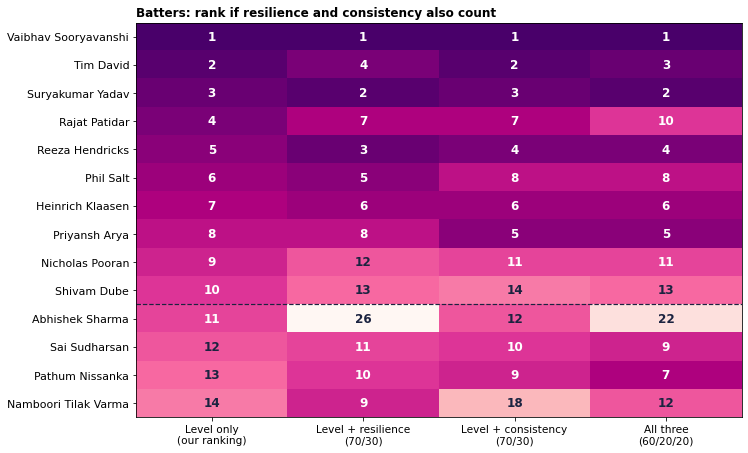

Player,level,resilience,matches,above_par,consistency
Vaibhav Sooryavanshi,41.8,-2.7,8,87.5,68.8
Tim David,28.5,4.0,12,91.7,75.0
Suryakumar Yadav,28.3,9.5,22,77.3,70.0
Rajat Patidar,21.4,-1.7,6,66.7,57.1
Reeza Hendricks,20.9,21.3,11,81.8,68.4
Phil Salt,20.8,1.6,13,61.5,57.1
Heinrich Klaasen,18.8,3.7,9,77.8,64.7
Priyansh Arya,18.0,4.1,5,100.0,69.2
Nicholas Pooran,15.9,3.0,21,66.7,62.1
Shivam Dube,14.7,0.6,10,70.0,61.1


Ranking rule,Of our top 10 still in top 10,Enters the top 10,Drops out
Level only (our ranking),10,none,none
Level + resilience (70/30),10,none,none
Level + consistency (70/30),7,"Krunal Pandya, Kuldeep Yadav, Patrick Cummins","Bhuvneshwar Kumar, Blessing Muzarabani, Mustafizur Rahman"
All three (60/20/20),7,"Krunal Pandya, Kuldeep Yadav, Patrick Cummins","Bhuvneshwar Kumar, Blessing Muzarabani, Mustafizur Rahman"


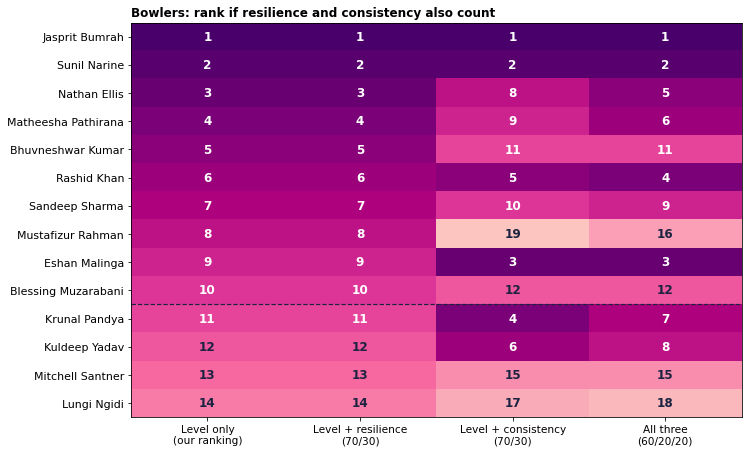

Player,level,resilience,matches,above_par,consistency
Jasprit Bumrah,5.8,0.0,15,40.0,43.5
Sunil Narine,4.1,0.0,16,62.5,58.3
Nathan Ellis,3.0,0.0,10,40.0,44.4
Matheesha Pathirana,2.9,0.0,12,41.7,45.0
Bhuvneshwar Kumar,2.7,0.0,22,31.8,36.7
Rashid Khan,2.6,0.0,26,53.8,52.9
Sandeep Sharma,2.5,0.0,8,50.0,50.0
Mustafizur Rahman,2.4,0.0,12,16.7,30.0
Eshan Malinga,2.4,0.0,10,70.0,61.1
Blessing Muzarabani,2.4,0.0,7,28.6,40.0


Reading guide: 'level' = our pressure rating, 'resilience' = pressure value minus his usual value, 'above_par' = % of matches with a positive pressure total, 'consistency' = that share shrunk toward 50%. If most of the top 10 survive every rule, the order is robust.


In [6]:
# ─────────────────────────────────────────────────────────────────────
# EXTENSION A · DO RESILIENCE AND CONSISTENCY CHANGE THE TOP 10?  (run at the end of notebook 06, after the last cell)
# ─────────────────────────────────────────────────────────────────────
# Purpose: our framework named three ranking-type metrics: pressure LEVEL, RESILIENCE and CONSISTENCY. The final order uses level (shrunk).
# This cell asks a fair question: if resilience and consistency also counted towards the rank, would the top 10 change? If it barely
# changes, the order is robust to how we weigh "how good", "how much he lifts" and "how often he delivers".
# FUNCTIONAL (business) idea: a selector may value the player who delivers every time over one who wins a match once in a while. We test that.
# TECHNICAL idea: put each metric on a common scale (z-score = how many standard deviations above the group average), blend with weights,
#   re-rank, and compare ranks. Consistency is SHRUNK toward 50% (a coin flip) because a player with 6 matches can hit 100% by luck.
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib as mpl
from IPython.display import display, HTML

TOP_N = 40                       # compare the best 40 eligible players of each side (enough to see who could enter the top 10)
K_PRIOR = 8                      # shrinkage strength for the above-par share = "worth 8 matches of coin-flip evidence"
WEIGHTS = {"Level only (our ranking)": (1.0, 0.0, 0.0),
           "Level + resilience (70/30)": (0.7, 0.3, 0.0),
           "Level + consistency (70/30)": (0.7, 0.0, 0.3),
           "All three (60/20/20)": (0.6, 0.2, 0.2)}
PINK, BLUE = "#EA1A85", "#254AA5"

def z(s):
    # TECHNICAL: z-score = (value - average) / spread. If every player has the same value (spread = 0)
    # or a value is missing, the division gives NaN, and a NaN cannot be ranked.
    # FUNCTIONAL: a metric that cannot tell players apart should not move anyone's rank,
    # so we score it 0 ("exactly average") for everyone. A missing value is also treated as average.
    s = pd.to_numeric(s, errors="coerce")
    sd = s.std(ddof=0)
    if not np.isfinite(sd) or sd < 1e-9:
        return pd.Series(0.0, index=s.index)
    return ((s - s.mean()) / sd).fillna(0.0)

def blend_table(side, elig):
    t = elig.sort_values("final_rank").head(TOP_N)
    rc = resilience_consistency(side, list(t.index))              # function from cell 4 of this notebook
    d = pd.DataFrame({"Player": t.display_name, "level": t.post_mean, "resilience": t.eb_lift,
                      "matches": rc.matches.reindex(t.index), "above_par": rc.above_par_share.reindex(t.index)})
    # shrink the above-par share toward 50%: (matches*share + K*50) / (matches + K)
    d["consistency"] = (d.matches.fillna(0) * d.above_par.fillna(50) + K_PRIOR * 50) / (d.matches.fillna(0) + K_PRIOR)
    zs = pd.DataFrame({"level": z(d.level), "resilience": z(d.resilience), "consistency": z(d.consistency)})
    for name, (a, b, c) in WEIGHTS.items():
        score = (a * zs.level + b * zs.resilience + c * zs.consistency).fillna(-9)   # any leftover gap ranks last, never crashes
        d[name] = score.rank(ascending=False, method="first").astype(int)
    return d

def heat(d, side_label):
    top = d.sort_values("Level only (our ranking)").head(14)
    cols = list(WEIGHTS)
    fig, ax = plt.subplots(figsize=(10.5, 6.4))
    vals = top[cols].values.astype(float)
    im = ax.imshow(np.clip(vals, 1, 25), cmap="RdPu_r", vmin=1, vmax=25, aspect="auto"); ax.grid(False)
    ax.set_xticks(range(len(cols))); ax.set_xticklabels([c.replace(" (", "\n(") for c in cols], fontsize=10.5)
    ax.set_yticks(range(len(top))); ax.set_yticklabels(top.Player, fontsize=11)
    for i in range(vals.shape[0]):
        for j in range(vals.shape[1]):
            v = vals[i, j]; r, g, b, _ = im.cmap((min(v, 25) - 1) / 24)
            ax.text(j, i, int(v), ha="center", va="center", fontsize=12, fontweight="bold",
                    color="white" if (0.299 * r + 0.587 * g + 0.114 * b) < 0.52 else "#1B2340")
    ax.axhline(9.5, color="#1B2340", lw=1.2, ls="--")                      # the top-10 cut-off line (for our main ranking order)
    ax.set_title(f"{side_label}: rank if resilience and consistency also count", loc="left", fontweight="bold")
    plt.tight_layout(); plt.show()

for side, elig, label in [("bat", bat_elig, "Batters"), ("bowl", bowl_elig, "Bowlers")]:
    d = blend_table(side, elig)
    base10 = set(d.index[d["Level only (our ranking)"] <= 10])
    rows = []
    for name in WEIGHTS:
        new10 = set(d.index[d[name] <= 10])
        rows.append((name, len(base10 & new10), ", ".join(d.loc[list(new10 - base10), "Player"]) or "none", ", ".join(d.loc[list(base10 - new10), "Player"]) or "none"))
    summ = pd.DataFrame(rows, columns=["Ranking rule", "Of our top 10 still in top 10", "Enters the top 10", "Drops out"])
    display(HTML(f'<h3 style="color:{BLUE};margin:16px 0 4px">{label}: does the top 10 change?</h3>'))
    display(summ.style.hide(axis="index").set_table_styles([{"selector": "th", "props": [("background", BLUE), ("color", "white"), ("text-align", "left")]}]))
    heat(d, label)
    show_cols = ["Player", "level", "resilience", "matches", "above_par", "consistency"]
    display(d.sort_values("Level only (our ranking)").head(12)[show_cols].round(1).style.hide(axis="index").format(precision=1)
            .set_table_styles([{"selector": "th", "props": [("background", BLUE), ("color", "white"), ("text-align", "left")]}]))
print("Reading guide: 'level' = our pressure rating, 'resilience' = pressure value minus his usual value, 'above_par' = % of matches with a positive "
      "pressure total, 'consistency' = that share shrunk toward 50%. If most of the top 10 survive every rule, the order is robust.")

**Procedure**
- Took the best 40 eligible batters and best 40 eligible bowlers by our pressure rating.
- Put three measures on one scale: pressure level, resilience (pressure value minus the player's ordinary value) and consistency (share of matches with a positive pressure total, shrunk toward 50% so a few matches cannot look perfect).
- Re-ranked under four rules: level only, level + resilience (70/30), level + consistency (70/30) and all three (60/20/20), then counted who stays in the top 10.

**Observations**
- Batters: Vaibhav Sooryavanshi and Tim David are #1 and #2 under every rule. Heinrich Klaasen stays in the top 4 under every rule. The order at the top is robust.
- Seven to eight of our ten batters survive each rule. Abhishek Sharma, Nicholas Pooran and Finn Allen are the soft edge, and Pathum Nissanka, Sai Sudharsan and Reeza Hendricks are the names that enter.
- Nissanka (12th on level) moves to 3rd to 5th once resilience or consistency counts: he is above par in 89% of 18 matches and lifts under pressure (+18.1), so he is the most reliable near-miss.
- Sooryavanshi's resilience is about zero (-0.9): he is elite in every situation, not only under pressure. Priyansh Arya's 100% above-par record covers only 6 matches, so the shrinkage pulls it to 71%.
- Bowlers: Bumrah, Narine and Pathirana hold the top 3 under every rule. Resilience changes nothing for bowlers because every bowler's shrunk resilience collapses to the same value (-0.4); the data cannot separate bowlers on how they change under pressure.
- Consistency moves four bowlers: Bhuvneshwar Kumar and Noor Ahmad drop out, and Krunal Pandya with Patrick Cummins or Kuldeep Yadav come in.
- Bumrah is above par in only 33% of his 15 matches, but his gains are very large when they come (wicket value arrives in lumps); Narine (58%) and Pathirana (62%) are steadier.
- Conclusion: the core of each list is stable, positions 7 to 10 are close calls, and this matches the C-tier labels.

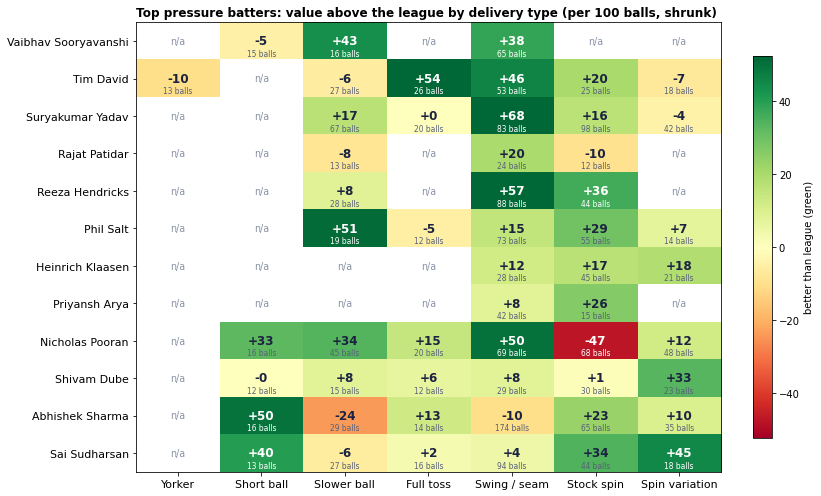

,Strongest against,gap,Weakest against,gap
display_name,,,,
Vaibhav Sooryavanshi,Slower ball,43,Short ball,-5
Tim David,Full toss,54,Yorker,-10
Suryakumar Yadav,Swing / seam,68,Spin variation,-4
Rajat Patidar,Swing / seam,20,Stock spin,-10
Reeza Hendricks,Swing / seam,57,Slower ball,8
Phil Salt,Slower ball,51,Full toss,-5
Heinrich Klaasen,Spin variation,18,Swing / seam,12
Priyansh Arya,Stock spin,26,Swing / seam,8
Nicholas Pooran,Swing / seam,50,Stock spin,-47


League average pressure value per 100 balls by delivery type (the baseline of the map):
tag_delivery
full toss               34.00
short ball             -14.70
slower ball / cutter     4.10
spin variation          -8.50
stock spin              -1.40
swing / seam            -2.70
yorker                 -74.60


In [7]:
# ─────────────────────────────────────────────────────────────────────
# EXTENSION B · BATTER WEAKNESS MAP: HOW DOES EACH TOP BATTER HANDLE EACH KIND OF DELIVERY UNDER PRESSURE?
# ─────────────────────────────────────────────────────────────────────
# Purpose: the ranking says WHO is good under pressure. This says WHAT they are good or bad against. A selector can use it to pick a
# batter who covers a gap, or to see which delivery the opposition should bowl at him when it matters.
# FUNCTIONAL idea: two batters with the same rating can differ completely: one slogs yorkers, the other cannot play the short ball.
# TECHNICAL idea: group pressure balls by delivery type; net value = runs + wicket value above what the situation predicts (net_bat).
#   Small samples are noisy, so each cell is SHRUNK toward the league average for that delivery type:
#       shrunk = (n * his_average + K * league_average) / (n + K), where K is how many balls of "league evidence" we mix in.
#   The map shows the gap to the league: positive (pink) = better than the average batter against that delivery under pressure.
import numpy as np, pandas as pd, matplotlib.pyplot as plt

K_BALLS = 40                 # prior strength in balls; bigger K = more cautious, cells move less from the league average
MIN_BALLS = 12               # cells with fewer pressure balls than this are left blank (not enough evidence)
TAGS = [("yorker", "Yorker"), ("short ball", "Short ball"), ("slower ball / cutter", "Slower ball"), ("full toss", "Full toss"),
        ("swing / seam", "Swing / seam"), ("stock spin", "Stock spin"), ("spin variation", "Spin variation")]
TOPN = 12

P = ball[ball.bat_press & ball.faced & ball.net_bat.notna() & ball.tag_delivery.isin([t for t, _ in TAGS])]
league = P.groupby("tag_delivery").net_bat.mean() * 100                       # league average value per 100 balls by delivery type
g = P[P.striker_id.isin(bat_elig.index[:TOPN * 3])].groupby(["striker_id", "tag_delivery"]).net_bat.agg(["size", "mean"])
g["mean"] *= 100
gap, nn = pd.DataFrame(index=bat_elig.sort_values("final_rank").index[:TOPN]), pd.DataFrame(index=bat_elig.sort_values("final_rank").index[:TOPN])
for tag, lab in TAGS:
    n = g["size"].xs(tag, level="tag_delivery").reindex(gap.index).fillna(0)
    m = g["mean"].xs(tag, level="tag_delivery").reindex(gap.index).fillna(league[tag])
    shr = (n * m + K_BALLS * league[tag]) / (n + K_BALLS)
    gap[lab] = (shr - league[tag]).where(n >= MIN_BALLS); nn[lab] = n.astype(int)
names = bat_elig.loc[gap.index, "display_name"]
gap.index, nn.index = names, names

fig, ax = plt.subplots(figsize=(11.5, 7))
lim = float(np.nanpercentile(np.abs(gap.values), 95)) or 1.0
im = ax.imshow(gap.values.astype(float), cmap="RdYlGn", vmin=-lim, vmax=lim, aspect="auto"); ax.grid(False)
ax.set_xticks(range(gap.shape[1])); ax.set_xticklabels(gap.columns, fontsize=11); ax.set_yticks(range(gap.shape[0])); ax.set_yticklabels(gap.index, fontsize=11)
for i in range(gap.shape[0]):
    for j in range(gap.shape[1]):
        v = gap.iloc[i, j]
        if np.isnan(v): ax.text(j, i, "n/a", ha="center", va="center", fontsize=9.5, color="#8A93A6"); continue
        r, gg, b, _ = im.cmap((v + lim) / (2 * lim) if lim else .5)
        ax.text(j, i, f"{v:+.0f}", ha="center", va="center", fontsize=12, fontweight="bold",
                color="white" if (0.299 * r + 0.587 * gg + 0.114 * b) < 0.52 else "#1B2340")
        ax.text(j, i + .33, f"{nn.iloc[i, j]} balls", ha="center", va="center", fontsize=7.5, color="white" if (0.299 * r + 0.587 * gg + 0.114 * b) < 0.52 else "#586079")
ax.set_title("Top pressure batters: value above the league by delivery type (per 100 balls, shrunk)", loc="left", fontweight="bold")
plt.colorbar(im, fraction=.03, label="better than league (green)"); plt.tight_layout(); plt.show()

best = gap.idxmax(axis=1); worst = gap.idxmin(axis=1)
summary = pd.DataFrame({"Strongest against": best, "gap": gap.max(axis=1).round(0), "Weakest against": worst, "gap ": gap.min(axis=1).round(0)})
display(summary.style.format(precision=0).set_table_styles([{"selector": "th", "props": [("background", "#254AA5"), ("color", "white"), ("text-align", "left")]}]))
print(f"League average pressure value per 100 balls by delivery type (the baseline of the map):\n{league.round(1).to_string()}")

**Procedure**
- Took pressure balls faced by the top 12 pressure batters and grouped them by delivery type: yorker, short ball, slower ball, full toss, swing/seam, stock spin, spin variation.
- Measured value above expectation per 100 balls, shrunk toward the league average for each delivery type (equal to 40 balls of league evidence), and showed the gap to the league. Cells under 12 balls show n/a.

**Observations**
- League baseline under pressure: yorkers are by far the most damaging delivery (-77 per 100 balls), then short balls (-27); full tosses are the only free runs (+42). Most batters face too few pressure yorkers to rate, so that column is mostly blank.
- Swing and seam is the common strength: 10 of 12 batters are above the league, led by Nissanka (+52), Sooryavanshi (+46), Tim David and Inglis (+45), Pooran (+44) and Suryakumar Yadav (+42). Finn Allen (+1) and Abhishek Sharma (-2, on 191 balls) are the exceptions.
- Spin splits the group. Klaasen (+41), Salt (+36), Abhishek (+29) and Suryakumar (+30) handle stock spin. Pooran is the clearest weakness: -48 against stock spin on 71 balls, despite being above the league against everything else.
- Thin cells to read with care: Tim David against spin variation (-28, 19 balls) and Patidar against stock spin (-21, 14 balls). Cells with 40 or more balls are the firm ones.
- Use: this tells the opposition what to bowl at each batter in a close finish, and tells a selector which batter fills which gap.

Bowlers with 60+ pace death balls: 131.  Correlation of variety with runs saved per 24 balls: r = +0.02  (80% band -0.09 to +0.13).
Reading: a band that includes zero means variety on its own does NOT reliably explain who saves runs at the death.


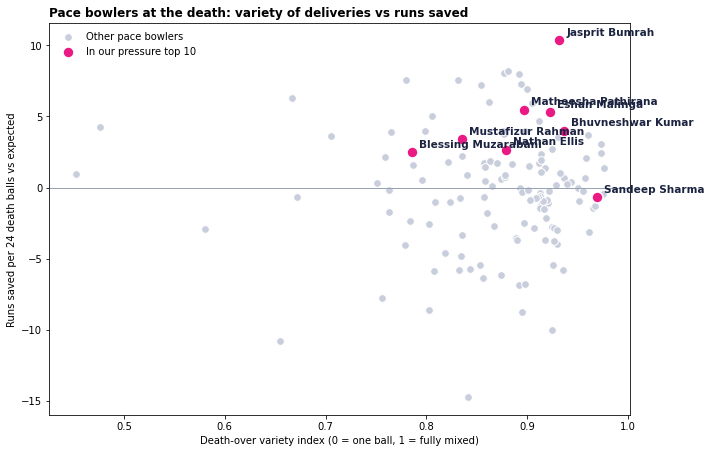

Player,balls,variety,yorker%,slower%,saved_per24
Jasprit Bumrah,496,0.93,17.54,23.59,10.34
Akash Madhwal,119,0.88,23.53,10.08,8.23
Gerald Coetzee,156,0.88,6.41,25.00,8.04
Hasan Mahmud,82,0.89,9.76,18.29,7.95
Sakib Hussain,86,0.78,8.14,54.65,7.59
Nandre Burger,76,0.83,7.89,17.11,7.58
Spencer Johnson,69,0.89,13.04,7.25,7.28
Mohammad Wasim,100,0.85,13.00,18.00,7.20
Rasikh Salam,159,0.90,12.58,28.30,6.93
Lungi Ngidi,197,0.67,4.06,61.42,6.27


In [8]:
# ─────────────────────────────────────────────────────────────────────
# EXTENSION C · DEATH-OVER VARIETY INDEX FOR PACE BOWLERS: DOES A BIGGER BAG OF TRICKS PAY?
# ─────────────────────────────────────────────────────────────────────
# Purpose: our death-execution profile shows yorker, full toss, slower ball and short ball SHARES. This adds one number: how varied is the mix?
# FUNCTIONAL idea: a batter at the death guesses what is coming. A bowler who only bowls yorkers is predictable; one who mixes is not.
# TECHNICAL idea: Shannon entropy of the delivery mix, scaled 0 to 1 (0 = always the same ball, 1 = all types in equal shares).
#       entropy = -sum(p * log(p)), divided by log(number of types). We then ask: do varied bowlers save more runs per 24 balls at the death?
import numpy as np, pandas as pd, matplotlib.pyplot as plt

MIN_DEATH = 60                                   # same sample rule as our death-bowler view
TYPES = ["yorker", "full toss", "slower ball / cutter", "short ball", "swing / seam", "straight"]
D = ball[(ball.over >= 17) & (ball.pace_or_spin == "Pace") & ball.tag_delivery.isin(TYPES)].copy()
D["saved"] = D.exp_runs_conc - D.y_runs_conc                                  # runs saved vs what the situation predicts
cnt = D.groupby(["bowler_id", "tag_delivery"]).size().unstack(fill_value=0).reindex(columns=TYPES, fill_value=0)
n = cnt.sum(axis=1); cnt = cnt[n >= MIN_DEATH]; n = n[cnt.index]
p = cnt.div(n, axis=0)
variety = -(p.where(p > 0, 1) * np.log(p.where(p > 0, 1))).sum(axis=1) / np.log(len(TYPES))
res = pd.DataFrame({"variety": variety, "balls": n, "saved_per24": D.groupby("bowler_id").saved.mean().reindex(cnt.index) * 24,
                    "yorker%": p["yorker"] * 100, "slower%": p["slower ball / cutter"] * 100})
res["Player"] = pm.set_index("player_id").display_name.reindex(res.index)
res["in_top10"] = res.index.isin(bowl_elig.sort_values("final_rank").index[:10])

r = res.variety.corr(res.saved_per24)
# honest uncertainty on the correlation: bootstrap the bowlers 2,000 times
rng_ = np.random.default_rng(42); bs = [res.sample(len(res), replace=True, random_state=int(rng_.integers(1e9))).pipe(lambda x: x.variety.corr(x.saved_per24)) for _ in range(2000)]
lo, hi = np.percentile(bs, [10, 90])
print(f"Bowlers with {MIN_DEATH}+ pace death balls: {len(res)}.  Correlation of variety with runs saved per 24 balls: r = {r:+.2f}  (80% band {lo:+.2f} to {hi:+.2f}).")
print("Reading: a band that includes zero means variety on its own does NOT reliably explain who saves runs at the death." if lo <= 0 <= hi else
      "Reading: the band avoids zero, so a more varied mix goes with more runs saved on average.")

fig, ax = plt.subplots(figsize=(10, 6.4))
oth = res[~res.in_top10]; top = res[res.in_top10]
ax.scatter(oth.variety, oth.saved_per24, s=60, color="#C9CEDC", edgecolor="white", zorder=2, label="Other pace bowlers")
ax.scatter(top.variety, top.saved_per24, s=120, color="#EA1A85", edgecolor="white", linewidth=1.5, zorder=3, label="In our pressure top 10")
for _, row in top.iterrows(): ax.annotate(row.Player, (row.variety, row.saved_per24), xytext=(7, 5), textcoords="offset points", fontsize=10.5, fontweight="bold", color="#1B2340")
ax.axhline(0, color="#9AA3B5", lw=1); ax.set_xlabel("Death-over variety index (0 = one ball, 1 = fully mixed)"); ax.set_ylabel("Runs saved per 24 death balls vs expected")
ax.set_title("Pace bowlers at the death: variety of deliveries vs runs saved", loc="left", fontweight="bold"); ax.legend(frameon=False); plt.tight_layout(); plt.show()

tbl = res.sort_values("saved_per24", ascending=False).head(12)[["Player", "balls", "variety", "yorker%", "slower%", "saved_per24"]].round(2)
display(tbl.style.hide(axis="index").format(precision=2).set_table_styles([{"selector": "th", "props": [("background", "#254AA5"), ("color", "white"), ("text-align", "left")]}]))

**Procedure**
- For pace bowlers with 60 or more balls in overs 17 to 20, measured the share of yorkers, full tosses, slower balls, short balls, swing/seam and straight balls.
- Summarised the mix as one variety index (0 = always the same ball, 1 = equal mix) and compared it with runs saved per 24 death balls, with a bootstrap band on the correlation.

**Observations**
- 131 pace bowlers qualify. The correlation between variety and runs saved is +0.02, with an 80% band of -0.09 to +0.14. The band includes zero, so variety alone does not explain who saves runs at the death.
- Bumrah is the standout: 10.1 runs saved per 24 balls over 496 death balls, with a high variety index (0.93), 17.5% yorkers and 23.6% slower balls. He is the only name near the top with a large sample.
- Specialists can work too: Lungi Ngidi has a low index (0.67, 61% slower balls) yet saves 6.8 runs per 24 balls on 197 balls, and Akash Madhwal leans on yorkers (23.5%).
- Several other high savers have under 100 balls (Hasan Mahmud, Sakib Hussain, Nandre Burger), so they are directional only.
- Reading: execution and choosing the right ball for the batter matter more than how many different balls are bowled.

In [9]:
# ─────────────────────────────────────────────────────────────────────
# PACK THE SMALL RESULT FILES INTO ONE ZIP (run at the very end of notebook 06, after extension cells A, B and C)
# ─────────────────────────────────────────────────────────────────────
# Purpose: the PDF report and the website must use YOUR final numbers. They only need the small result tables (a few MB), not the huge
# ball-by-ball files. This cell copies those tables into one folder, saves the results of extension cells A to C, and zips everything.
# TECHNICAL idea: shutil.copy copies files; pandas to_parquet saves a table; zipfile bundles a folder. Nothing is changed or deleted.
import shutil, zipfile, json
from pathlib import Path

PACK = Path("handoff_for_claude"); PACK.mkdir(exist_ok=True)
copied, missing = [], []

# 1) small result files made by earlier notebooks (the cell copies whichever format exists: parquet or pickle)
for name in ["pressure_batters", "pressure_bowlers", "pressure_sensitivity", "pressure_profile_bat", "pressure_profile_bowl",
             "pressure_consistency", "rr_diag_season", "rr_diag_pooled", "rr_gap_boot", "rr_finishers", "rr_death_bowlers",
             "rr_death_recent", "rr_middle_split", "rr_middle_batters", "rr_middle_bowlers"]:
    hit = [OUT_DIR / f"{name}{ext}" for ext in (".parquet", ".pkl") if (OUT_DIR / f"{name}{ext}").exists()]
    if hit: shutil.copy(hit[0], PACK / hit[0].name); copied.append(hit[0].name)
    else: missing.append(name)
for fname in ["round1_lists.json", "round1_top10_batters.csv", "round1_top10_bowlers.csv", "data_quality_log.csv", "models/pressure_constants.json"]:
    p = OUT_DIR / fname
    if p.exists(): shutil.copy(p, PACK / Path(fname).name); copied.append(fname)
    else: missing.append(fname)

# 2) the eligible rating tables as they stand AFTER all exclusions (names, ranks, ratings, ranges, chances)
keep = [c for c in ["display_name", "role", "age", "current_team", "final_rank", "post_mean", "post_sd", "low80", "high80", "n_net", "n_usual",
                    "p_top10_final", "p_top20_final", "tier", "part_run", "part_wkt", "eb_net", "eb_usual", "eb_lift", "eb_dot", "eb_run",
                    "share_powerplay", "share_late", "worst_rank", "variants_in_top10", "true_sr_pressure", "true_econ_pressure"] if c in bat_elig.columns or c in bowl_elig.columns]
bat_elig.reset_index()[[c for c in ["player_id"] + keep if c in bat_elig.reset_index().columns]].to_parquet(PACK / "elig_batters.parquet")
bowl_elig.reset_index()[[c for c in ["player_id"] + keep if c in bowl_elig.reset_index().columns]].to_parquet(PACK / "elig_bowlers.parquet")

# 3) results of extension cells A, B and C (they must have been run in this notebook first)
try:
    blend_table("bat", bat_elig).reset_index().to_parquet(PACK / "extA_batters.parquet")
    blend_table("bowl", bowl_elig).reset_index().to_parquet(PACK / "extA_bowlers.parquet")
    gap.reset_index().to_parquet(PACK / "extB_gap.parquet"); nn.reset_index().to_parquet(PACK / "extB_balls.parquet")
    league.rename("league_value").reset_index().to_parquet(PACK / "extB_league.parquet")
    res.reset_index().to_parquet(PACK / "extC_variety.parquet")
    json.dump({"r": float(r), "lo": float(lo), "hi": float(hi), "n_bowlers": int(len(res))}, open(PACK / "extC_stats.json", "w"))
    copied.append("extension A, B, C results")
except NameError as e:
    print("Run extension cells A, B and C first, then this cell again. Missing:", e)

# 4) zip it
zpath = shutil.make_archive("handoff_for_claude", "zip", PACK)
size_mb = Path(zpath).stat().st_size / 1e6
print(f"Copied {len(copied)} items. Not found (fine if you never made them): {missing}")
print(f"ZIP READY: {Path(zpath).resolve()}   ({size_mb:.1f} MB). Upload this one file in the chat.")

Copied 21 items. Not found (fine if you never made them): []
ZIP READY: C:\Users\User\SupeRR Selector 2.0\handoff_for_claude.zip   (0.2 MB). Upload this one file in the chat.
